Part 4B: Does NVDL deliver 2x the daily NVDA return?

**Question.** Regress daily NVDL returns on daily NVDA returns (with an intercept). Report coefficients and confidence intervals. Does this show whether NVDL meets its stated objective of 2 times the daily percentage change of NVDA?

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format

DATA = next(Path("../../data/raw").glob("*part 4*.xlsx"))
FIG = Path("../../output/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path("../../output/tables"); TAB.mkdir(parents=True, exist_ok=True)


raw = pd.read_excel(DATA, header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")
print(len(df), "trading days,", df.index.min().date(), "to", df.index.max().date())

147 trading days, 2024-02-01 to 2024-08-30


In [ ]:
import statsmodels.api as sm

X = sm.add_constant(df["NVDA"])
ols = sm.OLS(df["NVDL"], X).fit()
rob = ols.get_robustcov_results(cov_type="HC3")

ci = ols.conf_int(0.05)
res = pd.DataFrame({
    "Coefficient": ols.params,
    "Std. error": ols.bse,
    "t-stat": ols.tvalues,
    "95% CI low": ci[0],
    "95% CI high": ci[1],
})
res.index = ["Intercept (alpha, daily)", "Slope (beta on NVDA)"]
res.to_csv(TAB / "4B_regression.csv")
print(f"R-squared = {ols.rsquared:.5f}, residual std. dev. = {np.sqrt(ols.scale):.5f}, n = {int(ols.nobs)}")
res

R-squared = 0.99932, residual std. dev. = 0.00196, n = 147


,Coefficient,Std. error,t-stat,95% CI low,95% CI high
"Intercept (alpha, daily)",-0.0006,0.0002,-3.7430,-0.0009,-0.0003
Slope (beta on NVDA),1.9960,0.0043,460.4122,1.9874,2.0045


In [4]:
t_beta2 = ols.t_test("NVDA = 2")
print("H0: beta = 2")
print(f"  t-stat = {float(np.squeeze(t_beta2.tvalue)):.3f}, p-value = {float(np.squeeze(t_beta2.pvalue)):.3f}")
print("HC3-robust 95% CI for beta:", np.round(rob.conf_int()[1], 4))

H0: beta = 2
  t-stat = -0.928, p-value = 0.355
HC3-robust 95% CI for beta: [1.9836 2.0084]


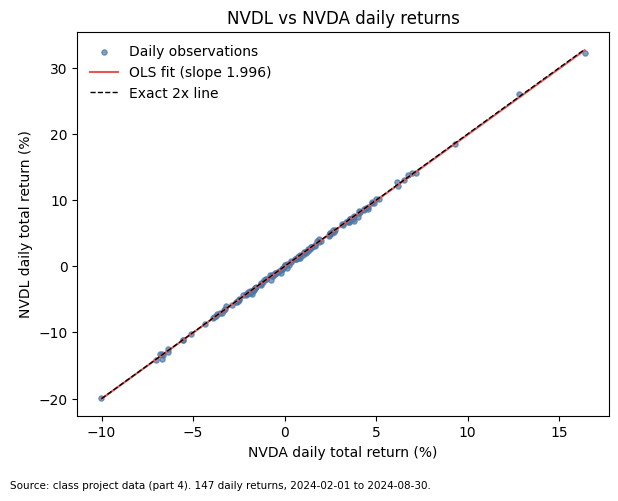

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.scatter(df["NVDA"] * 100, df["NVDL"] * 100, s=14, alpha=0.7, color="#4C78A8", label="Daily observations")
xs = np.linspace(df["NVDA"].min(), df["NVDA"].max(), 50)
ax.plot(xs * 100, (ols.params["const"] + ols.params["NVDA"] * xs) * 100, color="#E45756",
        label=f"OLS fit (slope {ols.params['NVDA']:.3f})")
ax.plot(xs * 100, 2 * xs * 100, "k--", lw=1, label="Exact 2x line")
ax.set_xlabel("NVDA daily total return (%)"); ax.set_ylabel("NVDL daily total return (%)")
ax.set_title("NVDL vs NVDA daily returns"); ax.legend(frameon=False)
fig.text(0.01, -0.03, "Source: class project data (part 4). 147 daily returns, 2024-02-01 to 2024-08-30.", fontsize=7.5)
plt.tight_layout(); fig.savefig(FIG / "4B_regression.png", bbox_inches="tight"); plt.show()